# Images for Hollow core guide

This notebook creates images associated with the input fields and resultant fields for the hollow core slab waveguide.  These images are used in documentary materials for the repo, website and visualizations.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from slabguide import Slab, Propagator, real_contour
from IPython.display import Image
from matplotlib.transforms import Bbox
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

%matplotlib widget
plt.style.use('dark_background')

In [5]:
img_path = '/home/pv/local/slabguide/images/Hollow_Core/'
website_path = '/home/pv/local/website/images/hollow_core/'
anim_path = img_path + '/anims/'

In [6]:
A = Slab(scale=1e-5, Ts=[6.5, 1, 6, 1, 6.5],  ns=[1, 1.44, 1, 1.44, 1],
                 xrefs=[100, 70, 300, 70, 100], wl=5.83e-06)

## Input fields

In [36]:
w = 1
s = .5
amp = 1

Lx = -w + s
Rx = w + s

def quadratic_piecewise(x):
    conds = [(x<Lx), ((Lx<=x)*(x<=Rx)), (x>Rx)]
    funcs = [0, lambda x: amp * (1 - ((x-s)/w)**2), 0]
    return np.piecewise(x, conds, funcs)

def quadratic_piecewise2d(x, zs=None, wavenumber=A.K0):
    conds = [(x<Lx), ((Lx<=x)*(x<=Rx)), (x>Rx)]
    funcs = [0, lambda x: amp * (1 - ((x-s)/w)**2), 0]
    fx = np.piecewise(x, conds, funcs)
    fz = np.exp(1j * wavenumber * zs)
    return np.outer(fz, fx) +.25

f0 = quadratic_piecewise

### Create Input field and RIP image for web use

Need these as thumbnails for clicking to link to visualizations on website.

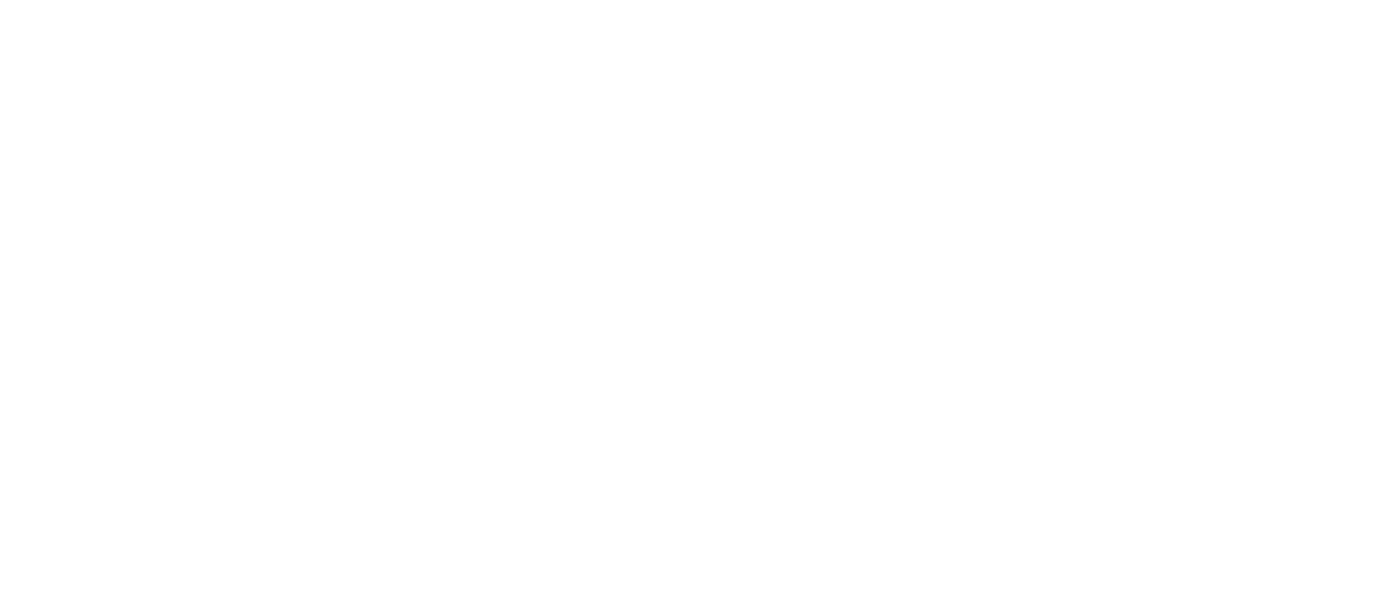

In [27]:
plt.close('all')
with plt.style.context('seaborn-v0_8-dark-palette'):
    fig, ax = A.plot_refractive_index(part='real', label='refractive index',
                                      figsize=(14,6), title_fontsize=25,lw=3);
    A.add_1d_plot(f0, label='input field', color='C0', lw=2.5, legend_fontsize=20);
    # ax.set_xticks([])
    ax.tick_params(axis='y', labelsize=18)
    ax.tick_params(axis='x', labelsize=18)
    fig.tight_layout();
plt.show();

In [28]:
# fig.savefig('/home/pv/local/website/images/basic_slab_RIP_and_input_dark.png', dpi=300)
# fig.savefig('/home/pv/local/slab/images/basic_slab_RIP_and_input_dark.png', dpi=300)

# 3D version

## Planes in 3D for slab waveguide face

In [10]:

width_center = 6
width_outer = 1
height = 15
center1 = np.array([0, 0, 0])

xdir = np.array([1, 0, 0])
ydir = np.array([0, 1, 0])
zdir = np.array([0, 0, 1])

def rect_verts(width, height, center=center1, dir1=xdir, dir2=zdir):
    return (center + np.array([dir1 * width / 2 - dir2 * height / 2,
                              dir1 * width / 2 + dir2 * height / 2,
                              -dir1 * width / 2 + dir2 * height / 2,
                              -dir1 * width / 2 - dir2 * height / 2]))[np.newaxis]

# Coordinates of rectangle
verts_center = rect_verts(width_center, height)
verts_right = rect_verts(width_outer, height, center1 + (width_center + width_outer)/2 * xdir)
verts_left = rect_verts(width_outer, height, center1 - (width_center + width_outer)/2 * xdir)

depth = 6
top_center = height/2 * zdir + depth/2 * ydir
verts_top_left = rect_verts(width_outer, depth,
                            top_center - (width_center + width_outer)/2 * xdir,
                            xdir, ydir)
verts_top_right = rect_verts(width_outer, depth,
                            top_center + (width_center + width_outer)/2 * xdir,
                            xdir, ydir)

verts_side_front = rect_verts(depth, height, 
                        (width_center/2 + width_outer) * xdir + depth/2 * ydir,
                        ydir, zdir)

verts_side_back = rect_verts(depth, height, 
                        -(width_center/2) * xdir + depth/2 * ydir,
                        ydir, zdir)

In [37]:
import matplotlib.colors as colors
cn = colors.CenteredNorm(-.25)

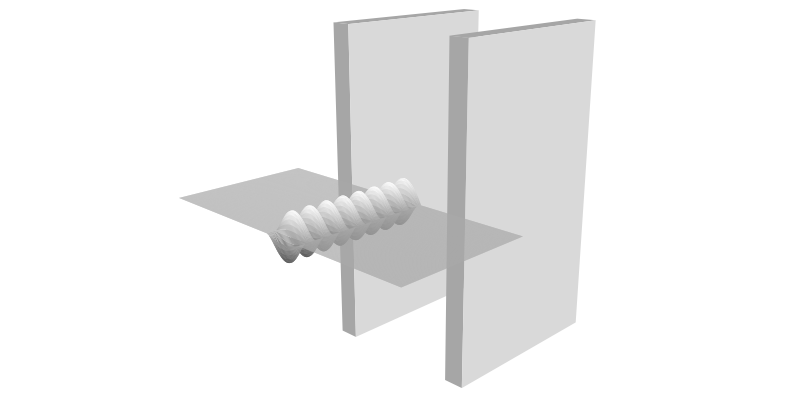

In [38]:
plt.close('all')

xs = np.concatenate([np.linspace(-(4*width_outer+.5*width_center), Lx, 2),
                     np.linspace(Lx, Rx, 30)[1:], 
                     np.linspace(Rx, (4*width_outer+.5*width_center), 2)[1:]])
# xs = np.linspace(Lx, Rx, 30)
with plt.style.context('default'):
    Fx = lambda x, y: quadratic_piecewise2d(x, y)
    fig, ax = A.plot_field_2d_surface(Fx, xs=xs,
                                      zmin=-4.5, zmax=0, zref=200, 
                                      xstride=1, zstride=1,
                                      # cmap=None,
                                      figsize=(8,4),
                                      cmap='gist_grey', show_axis=False,
                                      elev=18, azim=-46, roll=0,
                                      zoom=2, alpha=1, norm=cn
                                     )
    # fig.set_facecolor('red')
    # ax.set_aspect('equal')
    # ax.set_axis_on()
    ax.set_proj_type('persp', focal_length=0.5)
    # poly_center = Poly3DCollection(verts_center, color='.8', alpha=.1, lw=0, clip_on=False)
    poly_right = Poly3DCollection(verts_right, color='.65', alpha=1, lw=0, clip_on=False)
    poly_left = Poly3DCollection(verts_left, color='.65', alpha=1, lw=0, clip_on=False)
    poly_top_left = Poly3DCollection(verts_top_left, color='.65', alpha=1, lw=0, clip_on=False)
    poly_top_right = Poly3DCollection(verts_top_right, color='.65', alpha=1, lw=0, clip_on=False)
    poly_side_front = Poly3DCollection(verts_side_front, color='.85', alpha=1, lw=0, clip_on=False)
    poly_side_back = Poly3DCollection(verts_side_back, color='.85', alpha=1, lw=0, clip_on=False)
    # ax.add_collection3d(poly_center)
    ax.add_collection3d(poly_right)
    ax.add_collection3d(poly_left)
    ax.add_collection3d(poly_top_left)
    ax.add_collection3d(poly_top_right)
    ax.add_collection3d(poly_side_front)
    ax.add_collection3d(poly_side_back)
    ax.set_box_aspect((8,9,8), zoom=2)
    ax.set_facecolor(fig.get_facecolor())
    plt.show();
    # fig.tight_layout();


In [39]:
fig.bbox_inches

Bbox([[0.0, 0.0], [8.0, 4.0]])

In [40]:
box = Bbox([[.9, .35], [7.4, 4]])

In [41]:
fig.savefig('test.png', dpi=288, bbox_inches=box)

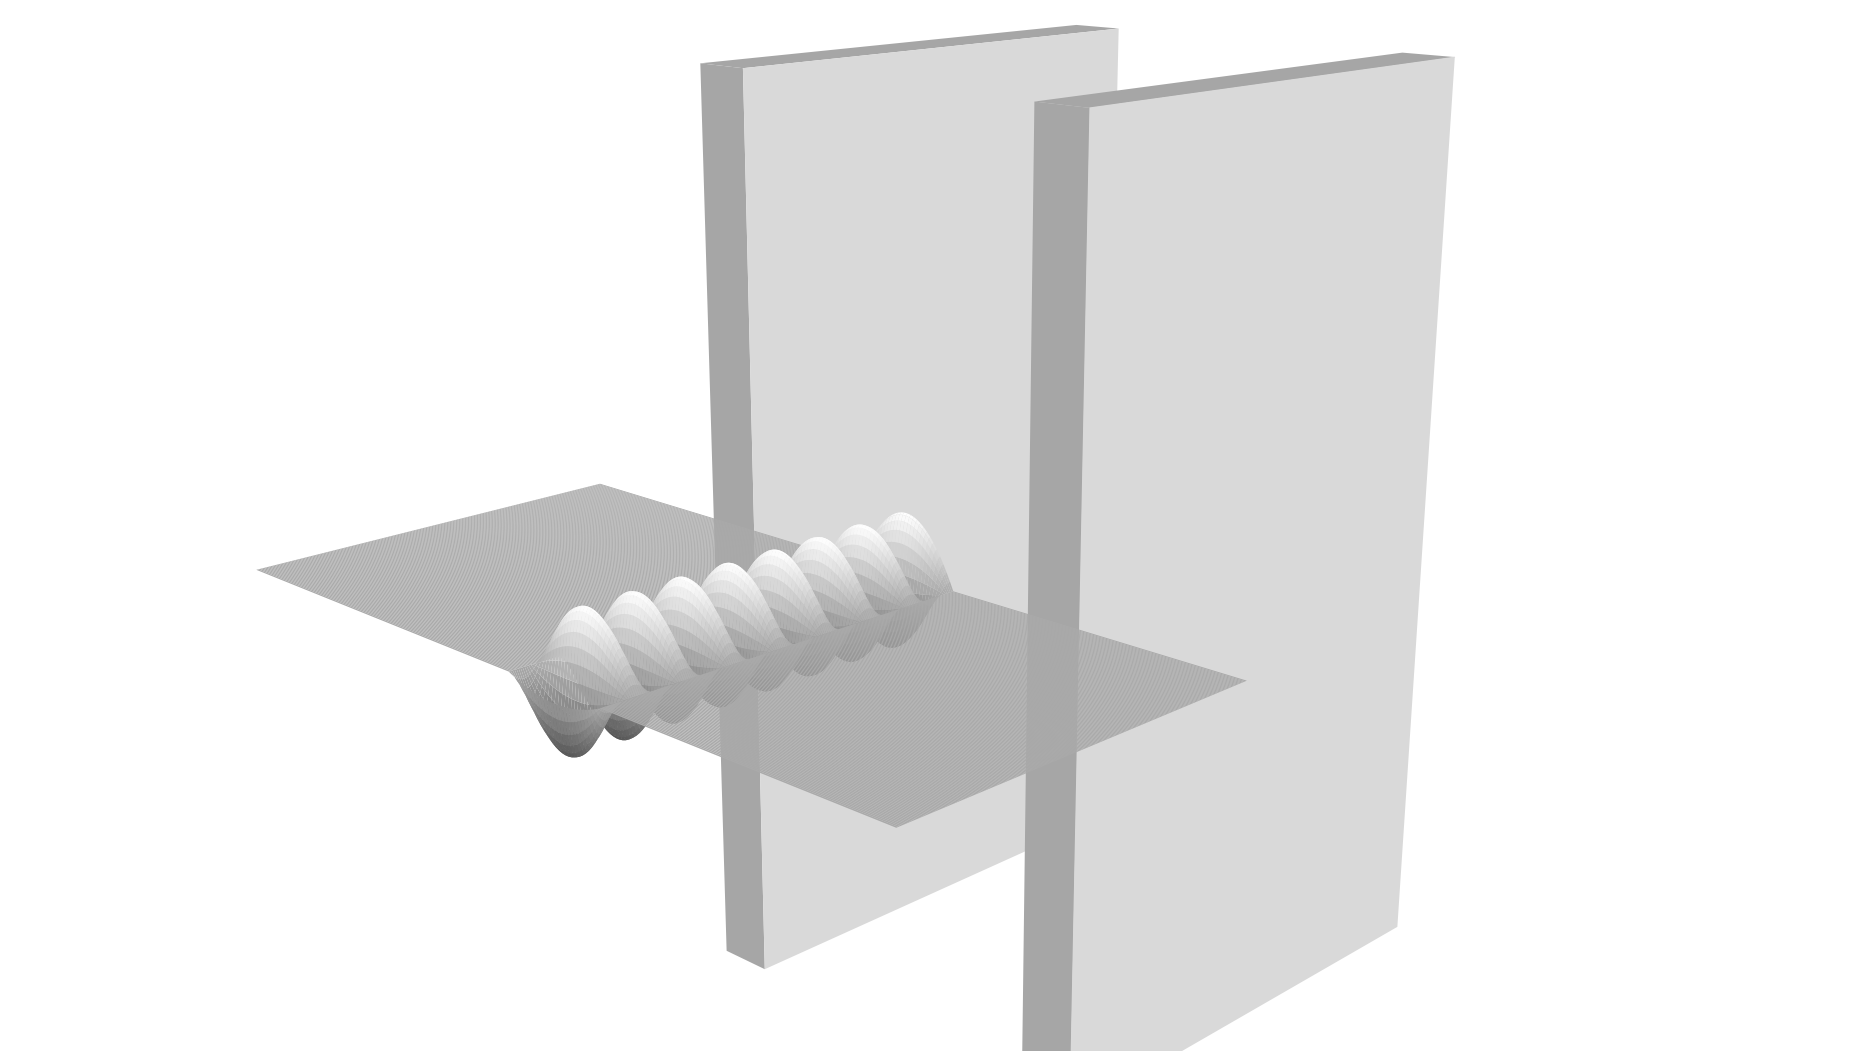

In [42]:
Image('test.png')

In [43]:
fig.savefig(website_path + '/3d_input_field_white.png', dpi=288, bbox_inches=box)

In [370]:
# fig.savefig(website_path + '/3d_input_field_transparent.png', transparent=True, dpi=288, bbox_inches=box)

In [16]:
# fig.savefig(img_path + '/3d_input_field_dark.png',dpi=288, bbox_inches=box)

# Resultant field images

In [16]:
P = Propagator(A, f0=f0, window=[Lx, Rx])

In [17]:
P.add_contour(real_contour(.0001, A.Z_evanescent, 100))
P.add_contour(real_contour(A.Z_evanescent, 10 * A.Z_evanescent, 150))

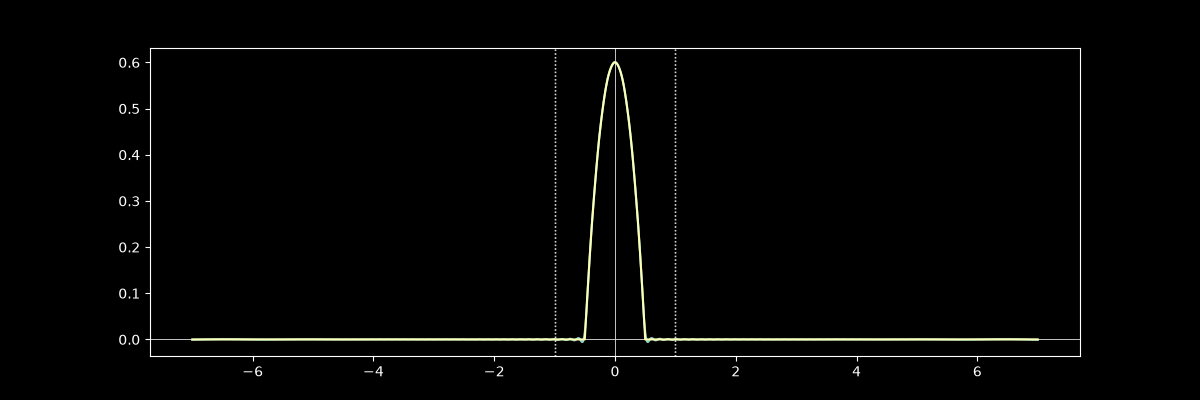

In [18]:
A.plot_field_1d(P, figsize=(12,4), part='real')
A.add_1d_plot(f0)
plt.show();

In [19]:
# A.plot_field_2d(Full, xs=np.linspace(-20,20,200), colorbar=False, figsize=(10,8),
#                 zmax=24, zref=200);

## Images

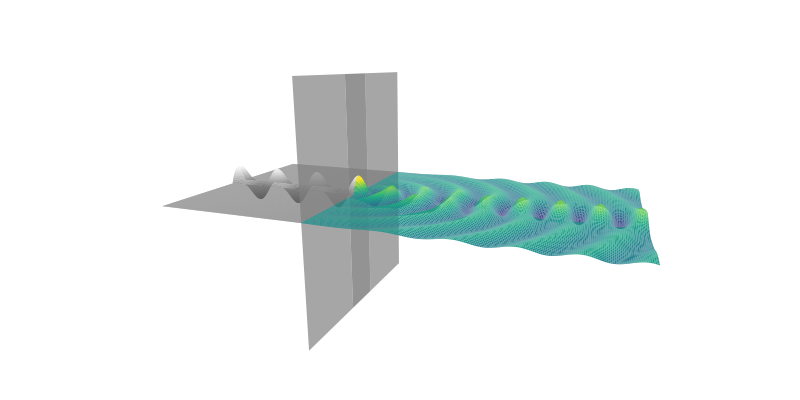

In [50]:
t = .1
with plt.style.context('default'):

    fig, ax = A.plot_field_2d_surface(P, xs=np.linspace(-(width_outer+.5*width_center), (width_outer+.5*width_center), 100), zs=np.linspace(0, 10, 200),
                                      xstride=1, zstride=1, t=t,
                                      elev=15, azim=20, roll=0,
                                      cmap='viridis', figsize=(8,4), zoom=1,
                                      alpha=1, vmin=-.8*amp, vmax=.8*amp,
                                     );
    A.add_2d_plot_surface(Fx, ax = ax, xs=xs, zmin=-5.5, zmax=0, zref=150, cmap='gray', t=t,
                         xstride=1, zstride=1, alpha=1);
    poly_center = Poly3DCollection(verts_center, color='.4', alpha=.7, lw=0, clip_on=False)
    poly_right = Poly3DCollection(verts_right, color='.5', alpha=.7, lw=0, clip_on=False)
    poly_left = Poly3DCollection(verts_left, color='.5', alpha=.7, lw=0, clip_on=False)
    ax.add_collection3d(poly_center)
    ax.add_collection3d(poly_right)
    ax.add_collection3d(poly_left);
    ax.set_box_aspect((8, 15.5, 8), zoom=1.9)
    # ax.set_aspect('equal')
    ax.set_proj_type('persp', focal_length=0.3)
    plt.show();

In [51]:
color = '#070072'
ax.set_facecolor(color)
fig.set_facecolor(color)

In [52]:
fig.bbox_inches

Bbox([[0.0, 0.0], [8.0, 4.0]])

In [53]:
box2 = Bbox([[1, .5], [7, 3.5]])

In [54]:
fig.savefig('test.png', dpi=288, bbox_inches=box2)

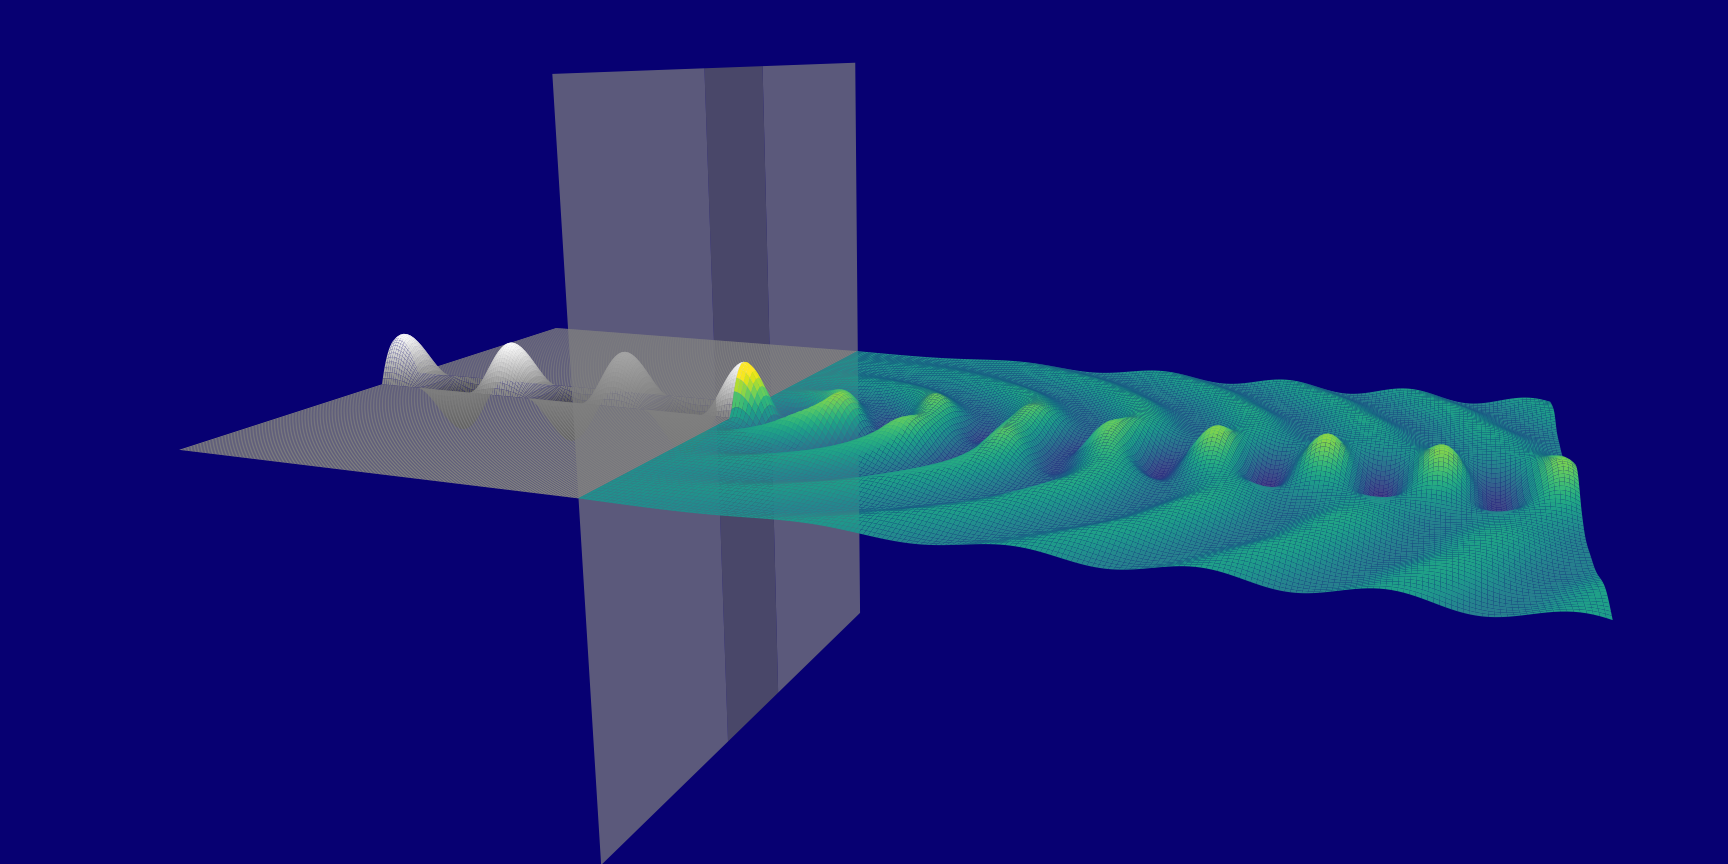

In [55]:
Image('test.png')

In [77]:
fig.savefig(img_path + '/3d_resultant_field_'+color[1:]+'.png', dpi=288, bbox_inches=box2)

In [82]:
fig.savefig(website_path + '/3d_resultant_field_'+color[1:]+'.png', dpi=288, bbox_inches=box2)

In [31]:
# fig.savefig('/home/pv/local/slab/images/3d_resultant_field_transparent.png', transparent=True, dpi=288, bbox_inches=box2)

In [30]:
# fig.savefig('/home/pv/local/slab/images/3d_resultant_field_dark.png', dpi=288, bbox_inches=box2)

## Animation Loop

In [56]:
Nt = 80
ts = np.linspace(0, 2 * np.pi, Nt)
base_data = P(np.linspace(-4, 4, 100), np.linspace(0, 10, 200))

In [57]:
for i,t in enumerate(ts):
    fig, ax = A.plot_field_2d_surface(P, xs=np.linspace(-(width_outer+.5*width_center), (width_outer+.5*width_center), 100), zs=np.linspace(0, 10, 200),
                                      xstride=1, zstride=1, t=t,
                                      elev=15, azim=20, roll=0,
                                      cmap='viridis', figsize=(8,4), zoom=1,
                                      alpha=1, vmin=-.8*amp, vmax=.8*amp,
                                     );
    A.add_2d_plot_surface(Fx, ax = ax, xs=xs, zmin=-5.5, zmax=0, zref=150, cmap='gray', t=t,
                         xstride=1, zstride=1, alpha=1);
    poly_center = Poly3DCollection(verts_center, color='.4', alpha=.7, lw=0, clip_on=False)
    poly_right = Poly3DCollection(verts_right, color='.5', alpha=.7, lw=0, clip_on=False)
    poly_left = Poly3DCollection(verts_left, color='.5', alpha=.7, lw=0, clip_on=False)
    ax.add_collection3d(poly_center)
    ax.add_collection3d(poly_right)
    ax.add_collection3d(poly_left);
    ax.set_box_aspect((8, 15.5, 8), zoom=1.9)
    # ax.set_aspect('equal')
    ax.set_proj_type('persp', focal_length=0.3)
    # plt.show();

    color = '#070072'
    ax.set_facecolor(color)
    fig.set_facecolor(color)
    
    box2 = Bbox([[1, .5], [7, 3.5]])
    fig.savefig(anim_path + '/'+str(i)+'.png', dpi=288, bbox_inches=box2)

In [29]:
ls anims


0.png   12.png  15.png  18.png  20.png  23.png  3.png  6.png  9.png
10.png  13.png  16.png  19.png  21.png  24.png  4.png  7.png  output.mp4
11.png  14.png  17.png  1.png   22.png  2.png   5.png  8.png


In [58]:
i = 72
t = ts[i]

fig, ax = A.plot_field_2d_surface(P, xs=np.linspace(-(width_outer+.5*width_center), (width_outer+.5*width_center), 100), zs=np.linspace(0, 10, 200),
                                  xstride=1, zstride=1, t=t,
                                  elev=15, azim=20, roll=0,
                                  cmap='viridis', figsize=(8,4), zoom=1,
                                  alpha=1, vmin=-.8*amp, vmax=.8*amp,
                                 );
A.add_2d_plot_surface(Fx, ax = ax, xs=xs, zmin=-5.5, zmax=0, zref=150, cmap='gray', t=t,
                     xstride=1, zstride=1, alpha=1);
poly_center = Poly3DCollection(verts_center, color='.4', alpha=.7, lw=0, clip_on=False)
poly_right = Poly3DCollection(verts_right, color='.5', alpha=.7, lw=0, clip_on=False)
poly_left = Poly3DCollection(verts_left, color='.5', alpha=.7, lw=0, clip_on=False)
ax.add_collection3d(poly_center)
ax.add_collection3d(poly_right)
ax.add_collection3d(poly_left);
ax.set_box_aspect((8, 15.5, 8), zoom=1.9)
# ax.set_aspect('equal')
ax.set_proj_type('persp', focal_length=0.3)
# plt.show();

color = '#070072'
ax.set_facecolor(color)
fig.set_facecolor(color)

box2 = Bbox([[1, .5], [7, 3.5]])
fig.savefig(anim_path + '/'+str(i)+'.png', dpi=288, bbox_inches=box2)

(<Figure size 1200x500 with 1 Axes>, <Axes: >)

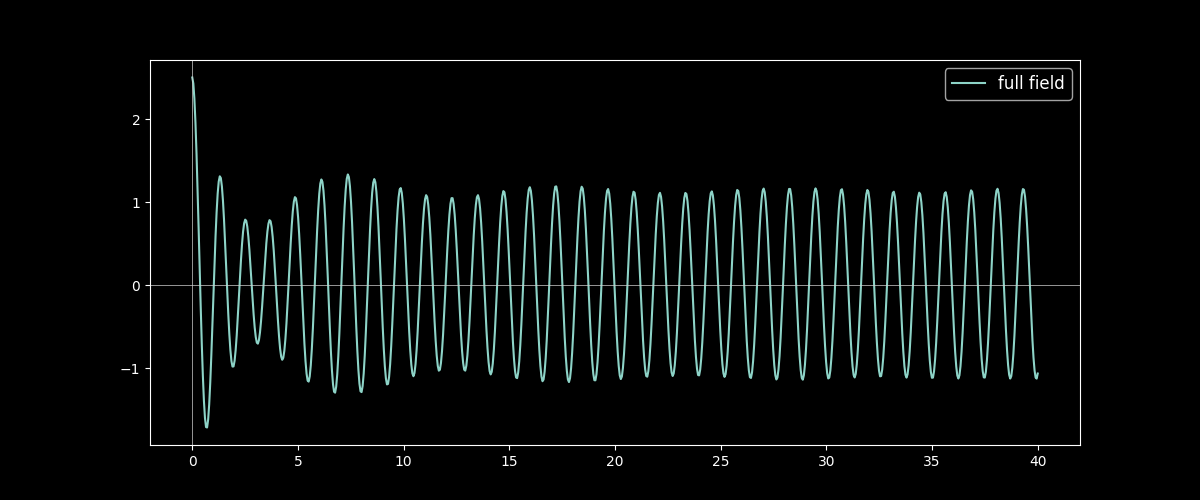

In [73]:
A.plot_field_1d(Full, zs=np.linspace(0, 40, 800), plot_Rhos=False, label='full field')

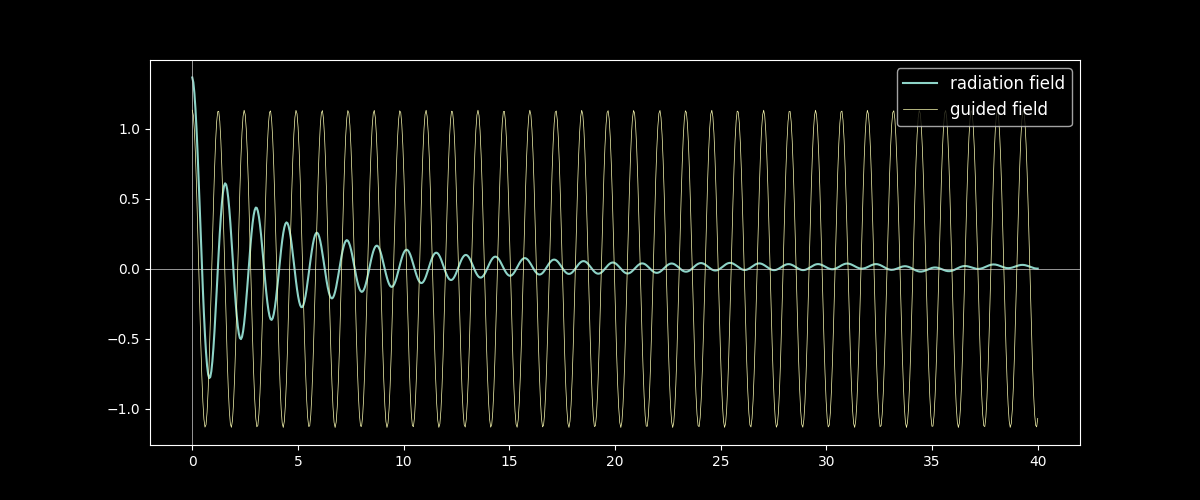

In [77]:
fig, ax = A.plot_field_1d(Rad, zs=np.linspace(0, 40, 800), plot_Rhos=False, label='radiation field')
A.add_1d_plot(Guided, zs=np.linspace(0, 40, 800), lw=.5, label='guided field')
